First 5 rows:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Original Shape: (200, 3)
Reduced Shape: (200, 2)

Eigenvalues:
[1.33465831 1.00427272]

Explained Variance Ratio:
PC1: 44.27%
PC2: 33.31%

Total Variance Retained: 77.57 %


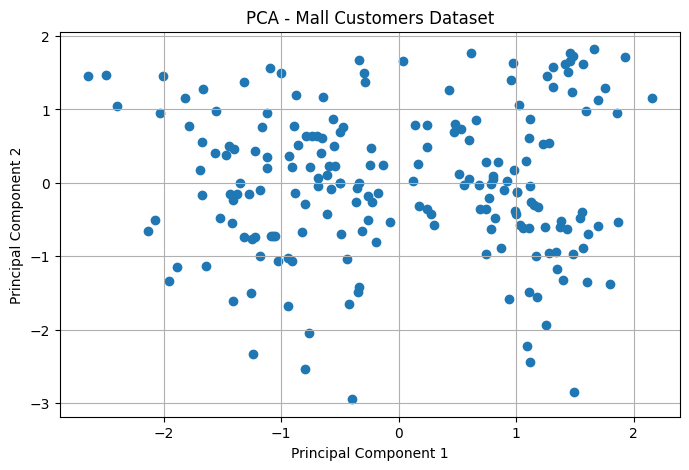


Reconstruction Error: 0.2243

Reduced Dataset:
        PC1       PC2
0  0.615720  1.763481
1  1.665793  1.820747
2 -0.337862  1.674799
3  1.456573  1.772430
4  0.038465  1.662740


In [4]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# 1. Load dataset
# 1. Load dataset
df = pd.read_csv('/content/Mall_Customers.csv')

print("First 5 rows:")
print(df.head())

# 2. Select numerical features
X = df[["Age", "Annual Income (k$)", "Spending Score (1-100)"]]

# 3. Standardize features
mean = X.mean().to_numpy()
std = X.std(ddof=0).to_numpy()
std[std == 0] = 1

X_scaled = (X.to_numpy() - mean) / std

# 4. Implement PCA manually
class PCA:

    def __init__(self, n_components=None):
        self.n_components = n_components

    def fit(self, X):
        X = np.asarray(X, dtype=float)

        # Center the data
        self.mean_ = np.mean(X, axis=0)
        X_centered = X - self.mean_

        # Covariance matrix
        cov_matrix = np.cov(X_centered, rowvar=False)

        # Eigenvalues and eigenvectors
        eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

        # Sort in descending order
        indices = np.argsort(eigenvalues)[::-1]
        eigenvalues = eigenvalues[indices]
        eigenvectors = eigenvectors[:, indices]

        # Explained variance ratio
        total_variance = np.sum(eigenvalues)
        self.explained_variance_ratio_ = (
            eigenvalues / total_variance
            if total_variance > 0
            else np.zeros_like(eigenvalues)
        )

        # Select principal components
        k = self.n_components
        self.components_ = eigenvectors[:, :k].T
        self.explained_variance_ = eigenvalues[:k]
        self.explained_variance_ratio_ = (
            self.explained_variance_ratio_[:k]
        )

        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        X_centered = X - self.mean_
        return np.dot(X_centered, self.components_.T)

    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)

    def inverse_transform(self, X_projected):
        return np.dot(X_projected, self.components_) + self.mean_


# 5. Reduce 3 features to 2 components
pca = PCA(n_components=2)
reduced_data = pca.fit_transform(X_scaled)

print("\nOriginal Shape:", X_scaled.shape)
print("Reduced Shape:", reduced_data.shape)

# 6. Display results
print("\nEigenvalues:")
print(pca.explained_variance_)

print("\nExplained Variance Ratio:")
for i, ratio in enumerate(pca.explained_variance_ratio_, 1):
    print(f"PC{i}: {ratio * 100:.2f}%")

print(
    "\nTotal Variance Retained:",
    round(np.sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

# 7. Plot principal components
plt.figure(figsize=(8, 5))
plt.scatter(reduced_data[:, 0], reduced_data[:, 1])
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - Mall Customers Dataset")
plt.grid(True)
plt.show()

# 8. Reconstruct and calculate error
reconstructed_data = pca.inverse_transform(reduced_data)

error = np.mean((X_scaled - reconstructed_data) ** 2)
print("\nReconstruction Error:", round(error, 4))

# 9. Display reduced dataset
result = pd.DataFrame(reduced_data, columns=["PC1", "PC2"])
print("\nReduced Dataset:")
print(result.head())
